**Step 1: Importing the necessary libraries**

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

**Step 2: Creating Custom Dataset**

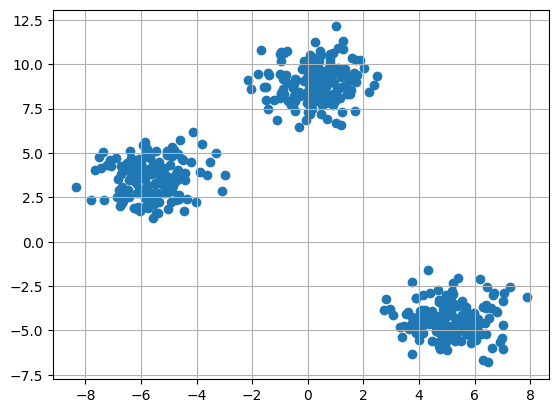

In [22]:
X,y = make_blobs(n_samples = 500, n_features=2, centers=3, random_state=23)

fig = plt.figure(0);
plt.grid(True)
plt.scatter(X[:,0],X[:,1])
plt.show()

**Step 3: Initializing Random Centroids**

In [23]:
k = 3
clusters = {}
np.random.seed(23)

for idx in range(k):
    center = 2*(2*np.random.random((X.shape[-1],))-1)
    points = []
    cluster = {
        'center' : center,
        'points' : []
    }
    clusters[idx] = cluster
clusters

{0: {'center': array([0.06919154, 1.78785042]), 'points': []},
 1: {'center': array([ 1.06183904, -0.87041662]), 'points': []},
 2: {'center': array([-1.11581855,  0.74488834]), 'points': []}}

**Step 4: Plotting Random Initialized Center with Data Points**

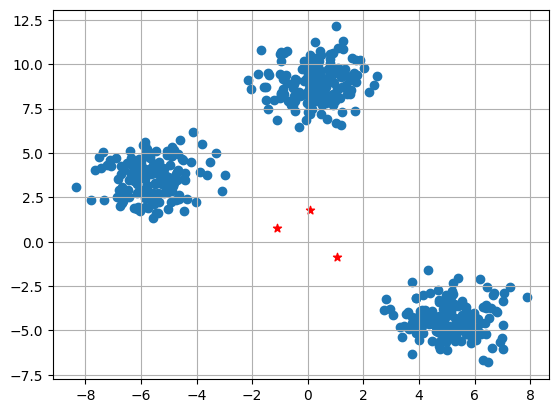

In [24]:
plt.scatter(X[:,0], X[:,-1])
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0], center[1], marker='*', c='red')

plt.show()

**Step 5: Defining Euclidean Distance**

In [25]:
def distance(p1,p2):
    return np.sqrt(np.sum((p1-p2)**2))

**Step 6: Creating Assign and Update Functions**

In [34]:
def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist = []
        
        curr_x = X[idx]
        
        for i in range(k):
            dis = distance(curr_x,clusters[i]['center'])
            dist.append(dis)
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]['points'].append(curr_x)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points = np.array(clusters[i]['points'])
        if points.shape[0] > 0:
            new_center = points.mean(axis =0)
            clusters[i]['center'] = new_center
            
            clusters[i]['points'] = []
    return clusters

**Step 7: Predicting the Cluster for the Data Points**

In [42]:
def pred_clusters(X, clusters):
    pred = []
    for i in range(X.shape[0]):
        dist = []
        for j in range(k):
            dist.append(distance(X[i], clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

**Step 8: Assigning, Updating and Predicting the Cluster Centers**

In [43]:
clusters = assign_clusters(X, clusters)
clusters = update_clusters(X, clusters)
pred = pred_clusters(X, clusters)

**Step 9: Plotting Data Points with Predicted Cluster Centers**

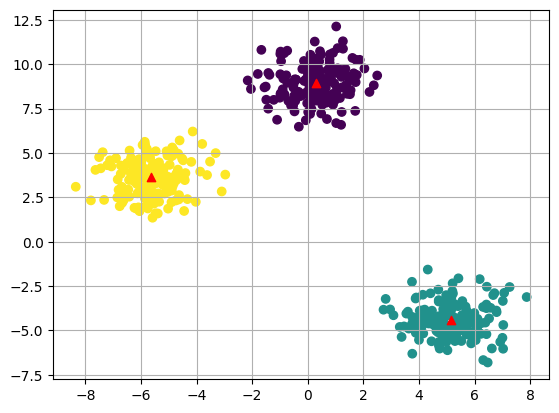

In [46]:
plt.scatter(X[:,0], X[:,1], c=pred)
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0], center[1], marker='^', c='red')
plt.show()